# 1. Imports and other

Definir carpeta raíz

In [1]:
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent
print(PROJECT_ROOT)

c:\Users\Carlos\Documents\Ingenieria_informatica\Proyectos_datascience\3_prediccion_precios_casas


Definir carpeta figures

In [2]:
FIGURES_PATH = PROJECT_ROOT / 'outputs' / 'figures'
print(FIGURES_PATH)

c:\Users\Carlos\Documents\Ingenieria_informatica\Proyectos_datascience\3_prediccion_precios_casas\outputs\figures


Añadir raíz al sys.path

In [3]:
import sys

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

print(sys.path)

['c:\\Users\\Carlos\\Documents\\Ingenieria_informatica\\Proyectos_datascience\\3_prediccion_precios_casas', 'C:\\Program Files\\WindowsApps\\PythonSoftwareFoundation.Python.3.13_3.13.3824.0_x64__qbz5n2kfra8p0\\python313.zip', 'C:\\Program Files\\WindowsApps\\PythonSoftwareFoundation.Python.3.13_3.13.3824.0_x64__qbz5n2kfra8p0\\DLLs', 'C:\\Program Files\\WindowsApps\\PythonSoftwareFoundation.Python.3.13_3.13.3824.0_x64__qbz5n2kfra8p0\\Lib', 'C:\\Program Files\\WindowsApps\\PythonSoftwareFoundation.Python.3.13_3.13.3824.0_x64__qbz5n2kfra8p0', 'c:\\Users\\Carlos\\Documents\\Ingenieria_informatica\\Proyectos_datascience\\3_prediccion_precios_casas\\venv', '', 'c:\\Users\\Carlos\\Documents\\Ingenieria_informatica\\Proyectos_datascience\\3_prediccion_precios_casas\\venv\\Lib\\site-packages']


Imports

In [4]:
import pandas as pd
from src.utils import simple_report
from src.visualizations import box_plot_project
import matplotlib.pyplot as plt

# 2. Read clean data

In [5]:
df = pd.read_csv(PROJECT_ROOT / 'data' / 'clean' / 'clean_train.csv')

In [6]:
df.head()

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NoAlleyAccess,Reg,Lvl,AllPub,...,0,NoPool,NoFence,NoMisceFeat,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NoAlleyAccess,Reg,Lvl,AllPub,...,0,NoPool,NoFence,NoMisceFeat,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NoAlleyAccess,IR1,Lvl,AllPub,...,0,NoPool,NoFence,NoMisceFeat,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NoAlleyAccess,IR1,Lvl,AllPub,...,0,NoPool,NoFence,NoMisceFeat,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NoAlleyAccess,IR1,Lvl,AllPub,...,0,NoPool,NoFence,NoMisceFeat,0,12,2008,WD,Normal,250000


In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   str    
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   str    
 6   Alley          1460 non-null   str    
 7   LotShape       1460 non-null   str    
 8   LandContour    1460 non-null   str    
 9   Utilities      1460 non-null   str    
 10  LotConfig      1460 non-null   str    
 11  LandSlope      1460 non-null   str    
 12  Neighborhood   1460 non-null   str    
 13  Condition1     1460 non-null   str    
 14  Condition2     1460 non-null   str    
 15  BldgType       1460 non-null   str    
 16  HouseStyle     1460 non-null   str    
 17  OverallQual    1460 non-null   int64  
 18  OverallCond    1460

Comprobar nulos restantes

In [8]:
remaining_nulls = df.isna().sum().reset_index()
remaining_nulls.columns = ['Feature', 'NaNs']
remaining_nulls = remaining_nulls[remaining_nulls['NaNs'] > 0]
remaining_nulls

,Feature,NaNs
3,LotFrontage,259
42,Electrical,1


# 3. Check features processed in data cleaning

Como agregamos categorías de no tener el feature/característica, revisaremos esas relaciones con el SalePrice

Los features interesantes para una revisión:

- PoolQC
- Fence
- GarageQual/GarageCond
- BsmtQual/BsmtCond

## 3.1 PoolQC

### 3.1.1 Simple report

In [9]:
simple_report(df, 'PoolQC', show_categories=True)


Nulls: 0
Dtype: str
Total categories: 4
Categories: ['NoPool', 'Ex', 'Fa', 'Gd']



### 3.1.2 Value counts

In [ ]:
df['PoolQC'].value_counts()

PoolQC
NoPool    1453
Gd           3
Ex           2
Fa           2
Name: count, dtype: int64

### 3.1.3 SalePrice by PoolQC

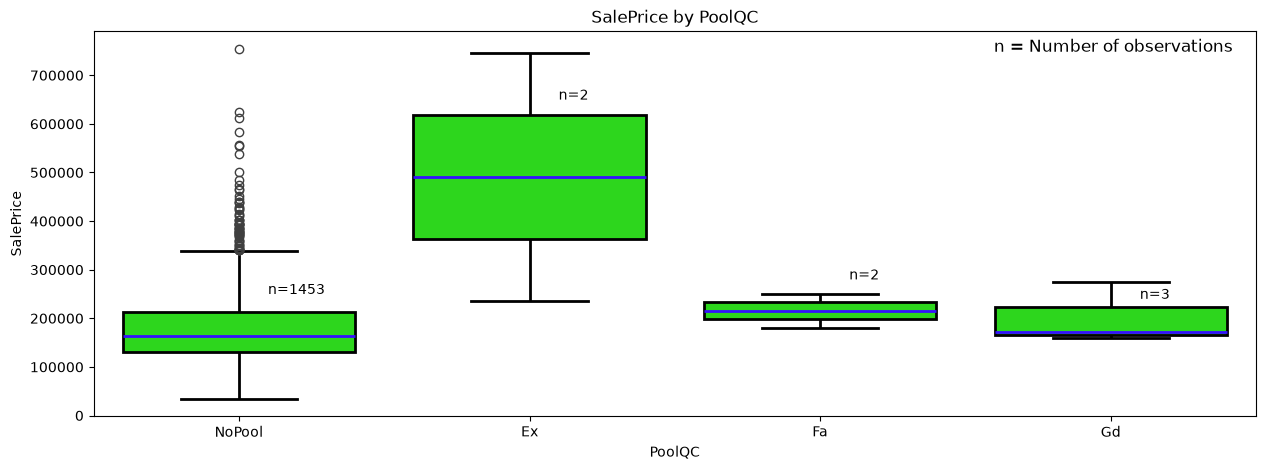

In [39]:
fig, ax = box_plot_project(
    df=df,
    x_name='PoolQC',
    y_name='SalePrice',
    title='SalePrice by PoolQC'
)

ax.annotate('n=1453', xy=(0.1, 250000))
ax.annotate('n=2', xy=(1.1, 650000))
ax.annotate('n=2', xy=(2.1, 280000))
ax.annotate('n=3', xy=(3.1, 240000))

ax.text(
    x=0.98,
    y=0.98,
    s='n = Number of observations',
    transform=ax.transAxes,
    ha='right',
    va='top',
    fontdict=dict(size=12, )
)


plt.savefig(FIGURES_PATH / '30_SalePrice_by_PoolQC', bbox_inches='tight')
plt.show()

## 3.2 Fence

### 3.2.1 Simple report

In [14]:
simple_report(df, 'Fence', show_categories=True)


Nulls: 0
Dtype: str
Total categories: 5
Categories: ['NoFence', 'MnPrv', 'GdWo', 'GdPrv', 'MnWw']



### 3.2.2 Value counts

In [15]:
df['Fence'].value_counts()

Fence
NoFence    1179
MnPrv       157
GdPrv        59
GdWo         54
MnWw         11
Name: count, dtype: int64

### 3.2.3 SalePrice by Fence

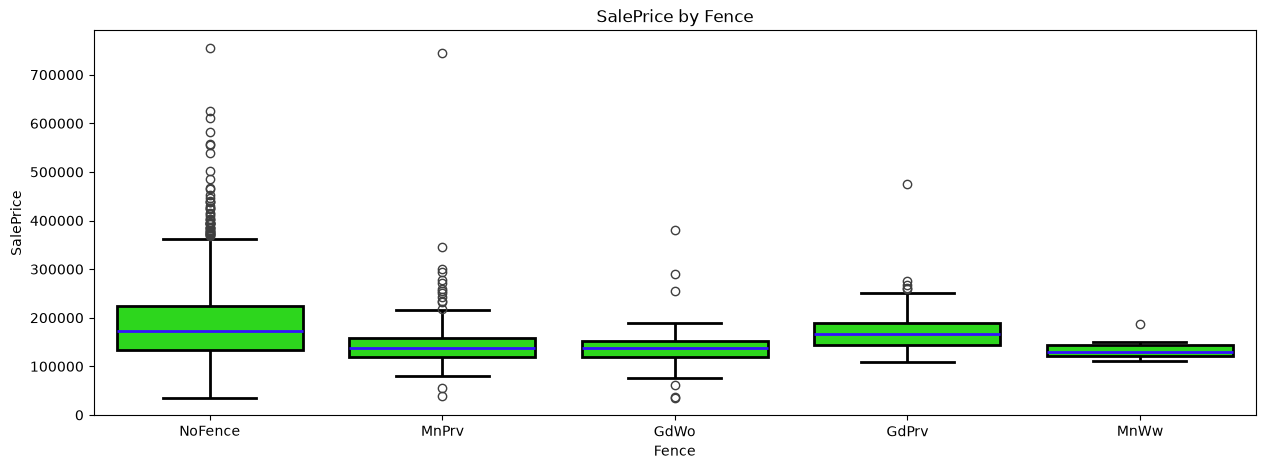

In [40]:
fig, ax = box_plot_project(
    df=df,
    x_name='Fence',
    y_name='SalePrice',
    title='SalePrice by Fence'
)


plt.savefig(FIGURES_PATH / '25_01_SalePrice_by_Fence_with_NoFence.png', bbox_inches='tight')
plt.show()

## 3.3 GarageQual

### 3.3.1 Simple report

In [62]:
simple_report(df, 'GarageQual', show_categories=True)


Nulls: 0
Dtype: str
Total categories: 6
Categories: ['TA', 'Fa', 'Gd', 'NoGarage', 'Ex', 'Po']



### 3.3.2 Value counts

In [50]:
df['GarageQual'].value_counts()

GarageQual
TA          1311
NoGarage      81
Fa            48
Gd            14
Ex             3
Po             3
Name: count, dtype: int64

### 3.3.3 SalePrice by GarageQual

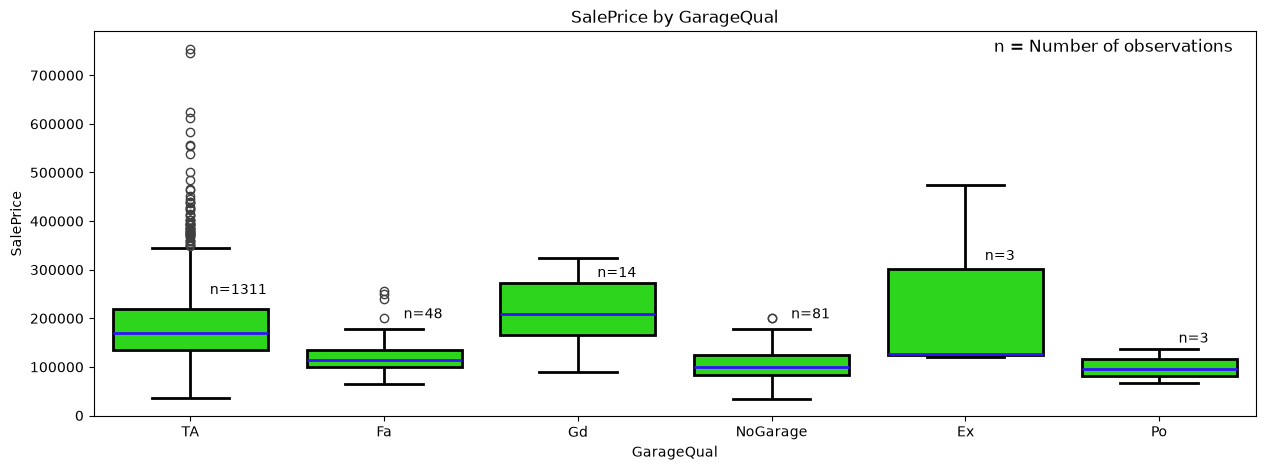

In [59]:
fig, ax = box_plot_project(
    df=df,
    x_name='GarageQual',
    y_name='SalePrice',
    title='SalePrice by GarageQual'
)



ax.annotate('n=1311', xy=(0.1, 250000))
ax.annotate('n=48', xy=(1.1, 200000))
ax.annotate('n=14', xy=(2.1, 285000))
ax.annotate('n=81', xy=(3.1, 200000))
ax.annotate('n=3', xy=(4.1, 320000))
ax.annotate('n=3', xy=(5.1, 150000))

ax.text(
    x=0.98,
    y=0.98,
    s='n = Number of observations',
    transform=ax.transAxes,
    ha='right',
    va='top',
    fontdict=dict(size=12)
)


plt.savefig(FIGURES_PATH / '23_01_SalePrice_by_GarageQual_with_NoGarage.png', bbox_inches='tight')
plt.show()

## 3.4 GarageCond

### 3.4.1 Simple report

In [61]:
simple_report(df, 'GarageCond', show_categories=True)


Nulls: 0
Dtype: str
Total categories: 6
Categories: ['TA', 'Fa', 'NoGarage', 'Gd', 'Po', 'Ex']



### 3.4.2 Value counts

In [63]:
df['GarageCond'].value_counts()

GarageCond
TA          1326
NoGarage      81
Fa            35
Gd             9
Po             7
Ex             2
Name: count, dtype: int64

### 3.3.3 SalePrice by GarageQual

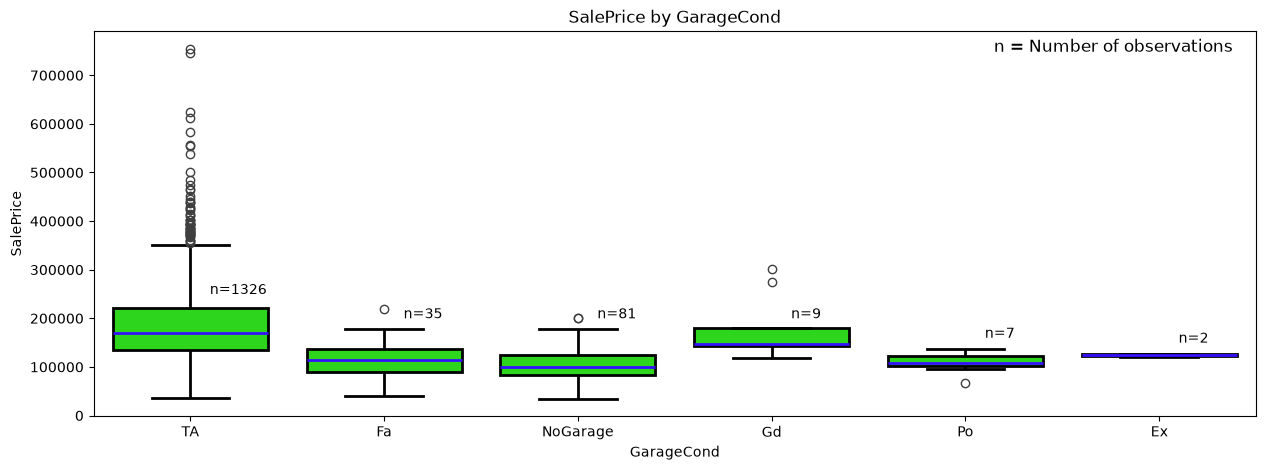

In [69]:
fig, ax = box_plot_project(
    df=df,
    x_name='GarageCond',
    y_name='SalePrice',
    title='SalePrice by GarageCond'
)



ax.annotate('n=1326', xy=(0.1, 250000))
ax.annotate('n=35', xy=(1.1, 200000))
ax.annotate('n=81', xy=(2.1, 200000))
ax.annotate('n=9', xy=(3.1, 200000))
ax.annotate('n=7', xy=(4.1, 160000))
ax.annotate('n=2', xy=(5.1, 150000))

ax.text(
    x=0.98,
    y=0.98,
    s='n = Number of observations',
    transform=ax.transAxes,
    ha='right',
    va='top',
    fontdict=dict(size=12)
)


#plt.savefig(FIGURES_PATH / '24_01_SalePrice_by_GarageCond_with_NoGarage.png', bbox_inches='tight')
plt.show()

## 3.5 BsmtQual

### 3.5.1 Simple report

In [71]:
simple_report(df, 'BsmtQual', show_categories=True)


Nulls: 0
Dtype: str
Total categories: 5
Categories: ['Gd', 'TA', 'Ex', 'NoBasement', 'Fa']



### 3.5.2 Value counts

In [72]:
df['BsmtQual'].value_counts()

BsmtQual
TA            649
Gd            618
Ex            121
NoBasement     37
Fa             35
Name: count, dtype: int64

### 3.5.3 SalePrice by BsmtQual

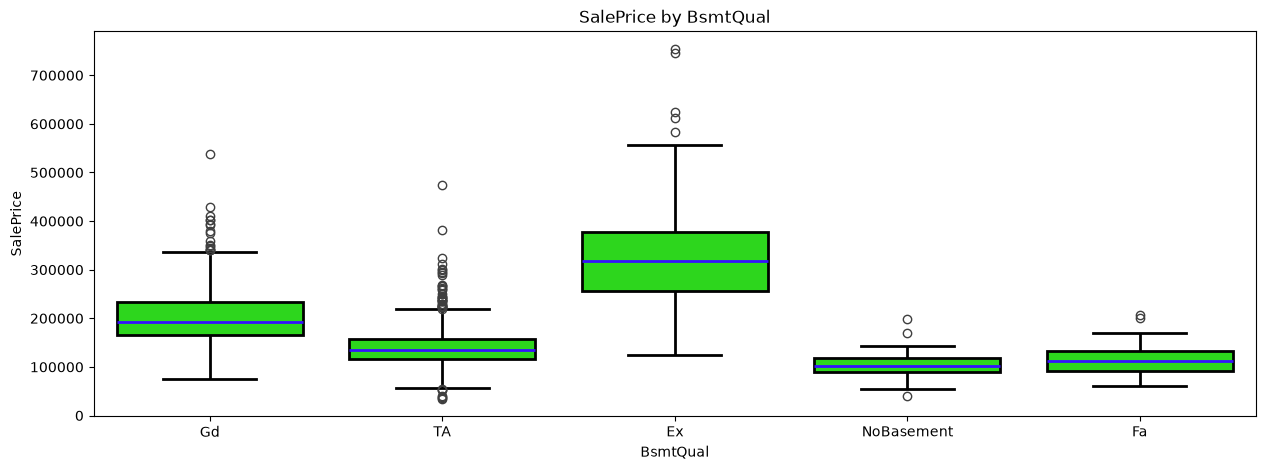

In [74]:
fig, ax = box_plot_project(
    df=df,
    x_name='BsmtQual',
    y_name='SalePrice',
    title='SalePrice by BsmtQual'
)

plt.savefig(FIGURES_PATH / '12_01_SalePrice_by_BsmtQual_with_NoBasement.png', bbox_inches='tight')
plt.show()

## 3.6 BsmtCond

### 3.6.1 Simple report

In [75]:
simple_report(df, 'BsmtCond', show_categories=True)


Nulls: 0
Dtype: str
Total categories: 5
Categories: ['TA', 'Gd', 'NoBasement', 'Fa', 'Po']



### 3.5.2 Value counts

In [76]:
df['BsmtCond'].value_counts()

BsmtCond
TA            1311
Gd              65
Fa              45
NoBasement      37
Po               2
Name: count, dtype: int64

### 3.5.3 SalePrice by BsmtQual

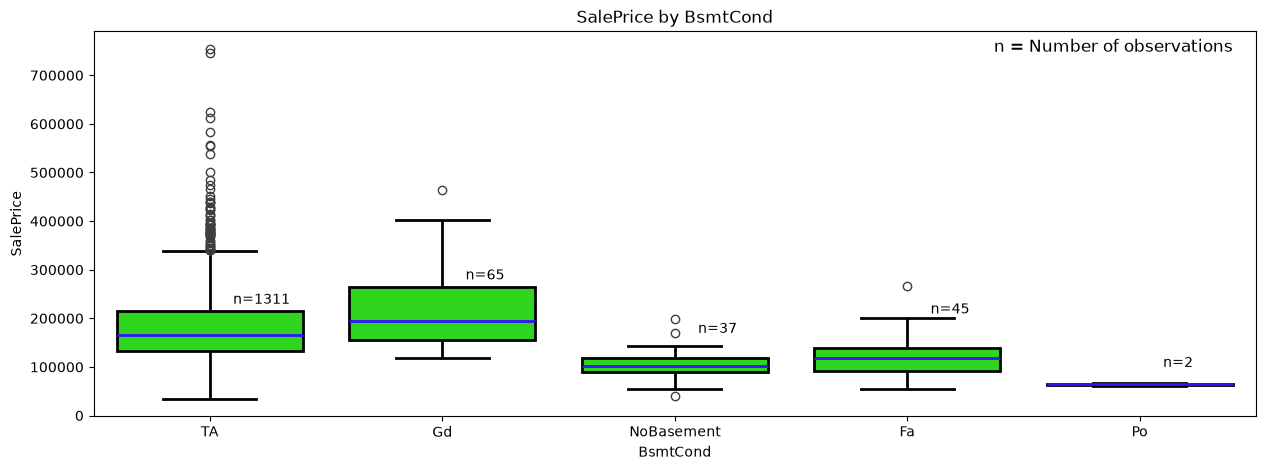

In [6]:
fig, ax = box_plot_project(
    df=df,
    x_name='BsmtCond',
    y_name='SalePrice',
    title='SalePrice by BsmtCond'
)

ax.annotate('n=1311', xy=(0.1, 230000))
ax.annotate('n=65', xy=(1.1, 280000))
ax.annotate('n=37', xy=(2.1, 170000))
ax.annotate('n=45', xy=(3.1, 210000))
ax.annotate('n=2', xy=(4.1, 100000))

ax.text(
    x=0.98,
    y=0.98,
    s='n = Number of observations',
    transform=ax.transAxes,
    ha='right',
    va='top',
    fontdict=dict(size=12)
)

plt.savefig(FIGURES_PATH / '13_01_SalePrice_by_BsmtCond_with_NoBasement.png', bbox_inches='tight')
plt.show()